# A/B Test Decision Review

**Descriptive analysis of the old page vs the new page**
> Scope: descriptive analytics only. No p-values, confidence intervals, or significance tests are used.

## Decision Brief

The question is simple: **does the treatment page outperform the control page enough to justify launch based on observed conversion behavior?**

The analysis uses one conversion outcome per user. Rows where experiment group and landing page disagree are removed before any rate is calculated. A repeated user is also reduced to the first valid exposure so the same person cannot contribute twice.

## Setup

The dataset is loaded directly from the local Downloads folder. No file discovery logic is needed for this task.

In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

visual_dir = Path('visuals')
visual_dir.mkdir(exist_ok=True)

data_path = r'C:\Users\anarrasulzada\Downloads\ab test data\ab_data.csv'

df = pd.read_csv(data_path)

print(df.shape)
df.head()



(294478, 5)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


## Integrity Gate

A/B results are only meaningful when the observed page matches the assigned group. Here the valid contract is:

- `control → old_page`
- `treatment → new_page`

Any cross-over is treated as a misassignment and excluded.

In [7]:
# compact source audit before any filtering
print(df.info())
print('\nmissing values')
display(df.isna().sum().to_frame('missing'))

# raw rates are shown only as a pre-cleaning checkpoint
raw_snapshot = (
    df.groupby('group', as_index=False)
      .agg(
          rows=('user_id', 'size'),
          raw_conversion_rate=('converted', 'mean')
      )
)
raw_snapshot['raw_conversion_rate_pct'] = raw_snapshot['raw_conversion_rate'] * 100
display(raw_snapshot)

print('\ngroup × landing page')
display(pd.crosstab(df['group'], df['landing_page']))

<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       294478 non-null  int64
 1   timestamp     294478 non-null  str  
 2   group         294478 non-null  str  
 3   landing_page  294478 non-null  str  
 4   converted     294478 non-null  int64
dtypes: int64(2), str(3)
memory usage: 11.2 MB
None

missing values


,missing
user_id,0
timestamp,0
group,0
landing_page,0
converted,0


,group,rows,raw_conversion_rate,raw_conversion_rate_pct
0,control,147202,0.120399,12.039918
1,treatment,147276,0.118920,11.891958



group × landing page


landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [8]:
# mismatches break the experiment contract
misassigned = (
    ((df['group'] == 'treatment') & (df['landing_page'] == 'old_page')) |
    ((df['group'] == 'control') & (df['landing_page'] == 'new_page'))
)

misassigned_count = int(misassigned.sum())
misassigned_share = misassigned.mean() * 100

print(f'misassigned rows: {misassigned_count:,}')
print(f'share of raw data: {misassigned_share:.3f}%')

misassigned rows: 3,893
share of raw data: 1.322%


The supplied CSV yields **3,893 misassigned rows (1.322%)**. The task note mentions 3,894; the direct cross-tab of this file returns 3,893, so the analysis follows the dataset rather than the reference note.

In [9]:
# only assignment-consistent rows move forward
clean = df.loc[~misassigned].copy()
clean['timestamp'] = pd.to_datetime(clean['timestamp'])

# one user should contribute one observed outcome
repeat_rows = clean['user_id'].duplicated().sum()
repeat_users = clean.loc[clean['user_id'].duplicated(keep=False), 'user_id'].nunique()

print(f'rows after assignment cleaning: {len(clean):,}')
print(f'duplicate rows by user_id: {repeat_rows:,}')
print(f'users appearing more than once: {repeat_users:,}')

rows after assignment cleaning: 290,585
duplicate rows by user_id: 1
users appearing more than once: 1


In [10]:
# the earliest valid record keeps the user grain stable
clean = (
    clean.sort_values('timestamp')
         .drop_duplicates('user_id', keep='first')
         .copy()
)

clean['date'] = clean['timestamp'].dt.date
clean['hour'] = clean['timestamp'].dt.hour

print(f'final analytical users: {len(clean):,}')
print(clean['group'].value_counts())

final analytical users: 290,584
group
treatment    145310
control      145274
Name: count, dtype: int64


In [11]:
# post-cleaning balance is checked before comparing outcomes
balance = (
    clean.groupby('group', as_index=False)
         .agg(users=('user_id', 'nunique'))
)
balance['share_pct'] = balance['users'] / balance['users'].sum() * 100
balance

,group,users,share_pct
0,control,145274,49.993806
1,treatment,145310,50.006194


After cleaning, the experiment contains **145,274 control users** and **145,310 treatment users** — a difference of only **36 users**. The split remains effectively 50/50, so the recommendation is not being driven by a materially unbalanced sample.

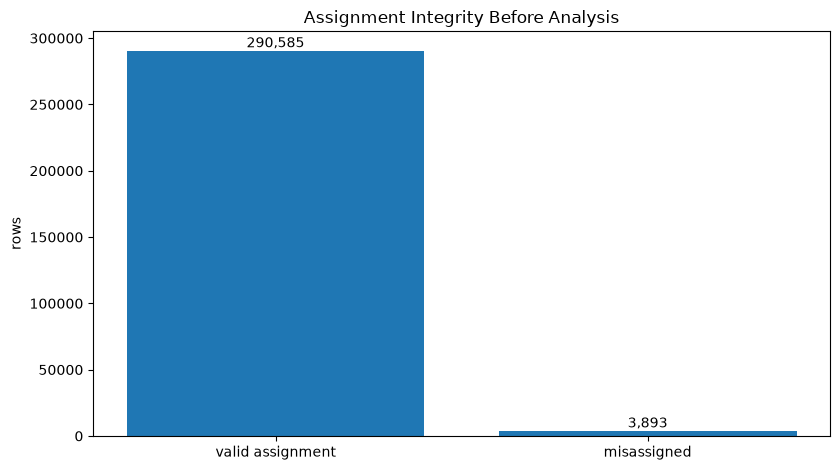

In [12]:
# a visual checkpoint makes the data loss explicit
quality = pd.DataFrame({
    'status': ['valid assignment', 'misassigned'],
    'rows': [len(df) - misassigned_count, misassigned_count]
})

plt.figure(figsize=(8.5, 4.8))
bars = plt.bar(quality['status'], quality['rows'])
plt.title('Assignment Integrity Before Analysis')
plt.ylabel('rows')
plt.ticklabel_format(style='plain', axis='y')
for bar, value in zip(bars, quality['rows']):
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value:,}', ha='center', va='bottom')
plt.tight_layout()
plt.savefig(visual_dir / 'assignment integrity.png', dpi=180, bbox_inches='tight')
plt.show()

## The Outcome Gap

Conversion rate is calculated at user level:

\[
	ext{conversion rate} = 
rac{	ext{converted users}}{	ext{users}} 	imes 100
\]

The summary table is the main decision surface. Absolute difference is expressed in **percentage points**, while relative difference compares the treatment rate with the control baseline.

In [13]:
# group-level outcome table used throughout the decision section
summary = (
    clean.groupby('group', as_index=False)
         .agg(
             user_count=('user_id', 'nunique'),
             conversions=('converted', 'sum'),
             conversion_rate=('converted', 'mean')
         )
)
summary['conversion_rate_pct'] = summary['conversion_rate'] * 100
summary['non_converted'] = summary['user_count'] - summary['conversions']
summary

,group,user_count,conversions,conversion_rate,conversion_rate_pct,non_converted
0,control,145274,17489,0.120386,12.038630,127785
1,treatment,145310,17264,0.118808,11.880807,128046


In [14]:
# two lenses on the same observed gap
rates = summary.set_index('group')['conversion_rate']
control_rate = rates['control']
treatment_rate = rates['treatment']

absolute_diff_pp = (treatment_rate - control_rate) * 100
relative_diff_pct = (treatment_rate / control_rate - 1) * 100

print(f'control conversion rate:   {control_rate:.4%}')
print(f'treatment conversion rate: {treatment_rate:.4%}')
print(f'absolute difference:       {absolute_diff_pp:.3f} pp')
print(f'relative difference:       {relative_diff_pct:.3f}%')

control conversion rate:   12.0386%
treatment conversion rate: 11.8808%
absolute difference:       -0.158 pp
relative difference:       -1.311%


Observed conversion is **12.04% for control** and **11.88% for treatment**. Treatment trails by **0.158 percentage points**, equivalent to a **1.31% relative decrease** from the control baseline.

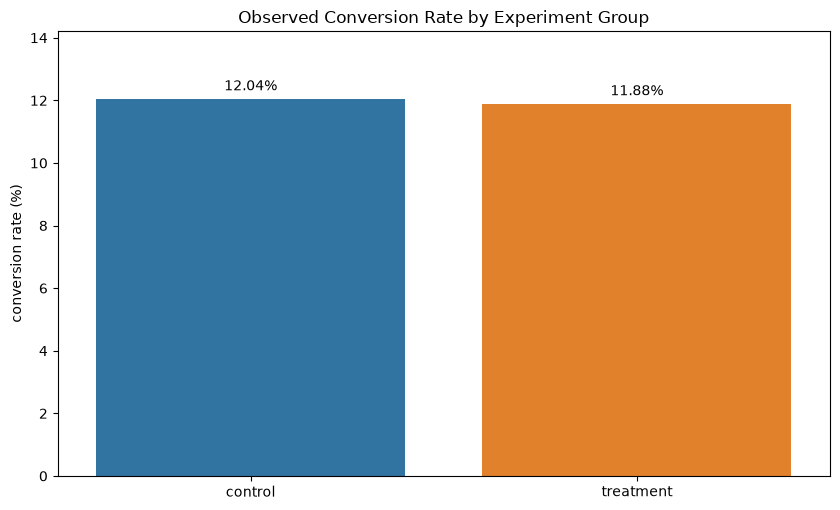

In [15]:
# side-by-side comparison keeps the decision metric visible
plt.figure(figsize=(8.5, 5.2))
ax = sns.barplot(data=summary, x='group', y='conversion_rate_pct', hue='group', legend=False)
plt.title('Observed Conversion Rate by Experiment Group')
plt.xlabel('')
plt.ylabel('conversion rate (%)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=4)
plt.ylim(0, summary['conversion_rate_pct'].max() * 1.18)
plt.tight_layout()
plt.savefig(visual_dir / 'conversion rate comparison.png', dpi=180, bbox_inches='tight')
plt.show()

### Funnel View

The funnel uses actual user counts rather than normalized percentages. This makes the scale of the experiment visible alongside the final converted population.

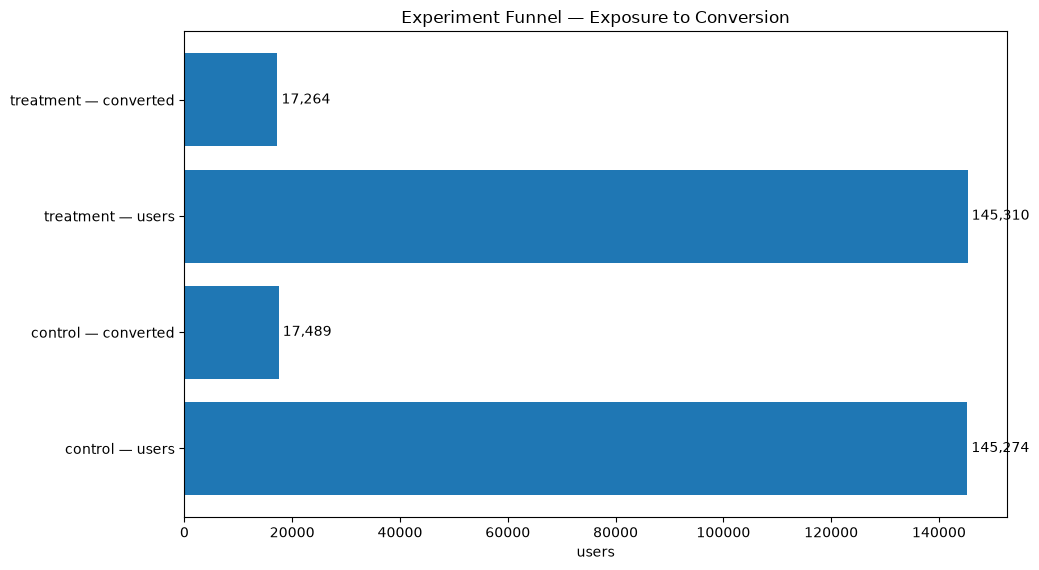

In [16]:
# each group keeps its own exposure-to-conversion path
funnel = pd.DataFrame({
    'stage': [
        'control — users', 'control — converted',
        'treatment — users', 'treatment — converted'
    ],
    'count': [
        int(summary.loc[summary['group'].eq('control'), 'user_count'].iloc[0]),
        int(summary.loc[summary['group'].eq('control'), 'conversions'].iloc[0]),
        int(summary.loc[summary['group'].eq('treatment'), 'user_count'].iloc[0]),
        int(summary.loc[summary['group'].eq('treatment'), 'conversions'].iloc[0])
    ]
})

plt.figure(figsize=(10.5, 5.8))
bars = plt.barh(funnel['stage'], funnel['count'])
plt.title('Experiment Funnel — Exposure to Conversion')
plt.xlabel('users')
plt.ticklabel_format(style='plain', axis='x')
for bar, value in zip(bars, funnel['count']):
    plt.text(value, bar.get_y() + bar.get_height()/2, f' {value:,}', va='center')
plt.tight_layout()
plt.savefig(visual_dir / 'conversion funnel.png', dpi=180, bbox_inches='tight')
plt.show()

## Stability Over Time

A one-number winner can hide a temporary spike or rollout artifact. Daily conversion is therefore checked for both groups across the experiment window. The first and last dates are partial days, so they are interpreted as boundary observations rather than full-day benchmarks.

In [17]:
# calendar date isolates day-level movement
by_day = (
    clean.groupby(['date', 'group'], as_index=False)
         .agg(
             users=('user_id', 'nunique'),
             conversions=('converted', 'sum'),
             conversion_rate=('converted', 'mean')
         )
)
by_day['conversion_rate_pct'] = by_day['conversion_rate'] * 100
by_day.head()

,date,group,users,conversions,conversion_rate,conversion_rate_pct
0,2017-01-02,control,2859,359,0.125568,12.556838
1,2017-01-02,treatment,2853,342,0.119874,11.987382
2,2017-01-03,control,6590,750,0.113809,11.380880
3,2017-01-03,treatment,6618,753,0.113781,11.378060
4,2017-01-04,control,6578,802,0.121922,12.192156


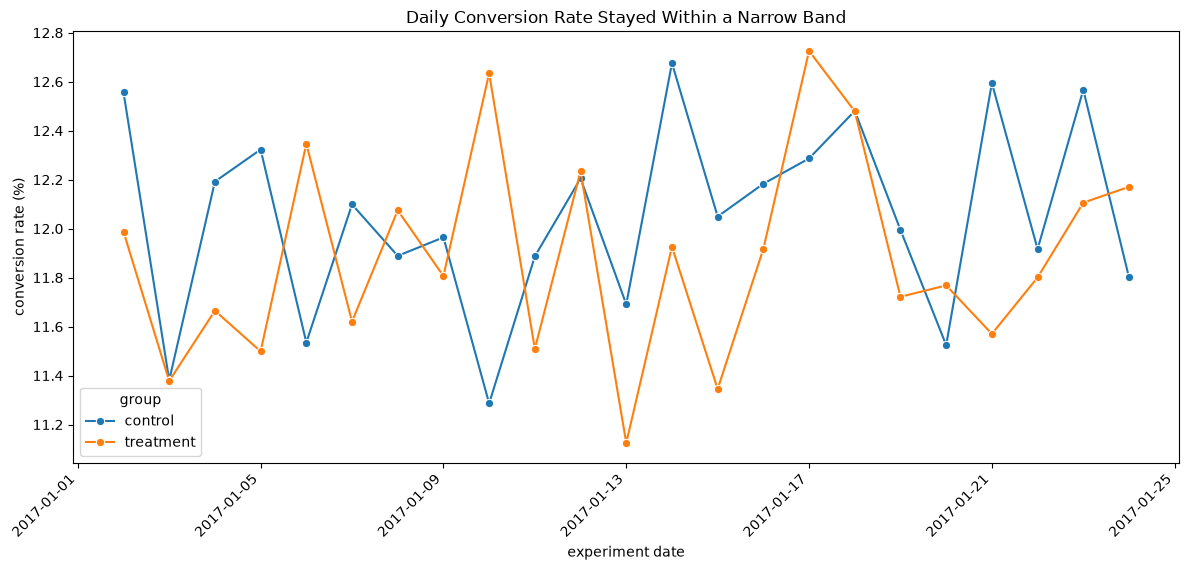

In [18]:
# the line view checks whether one period dominates the result
plt.figure(figsize=(12, 5.8))
sns.lineplot(
    data=by_day,
    x='date',
    y='conversion_rate_pct',
    hue='group',
    marker='o'
)
plt.title('Daily Conversion Rate Stayed Within a Narrow Band')
plt.xlabel('experiment date')
plt.ylabel('conversion rate (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='group')
plt.tight_layout()
plt.savefig(visual_dir / 'daily conversion rate.png', dpi=180, bbox_inches='tight')
plt.show()

In [19]:
# daily gaps reveal how often the treatment actually leads
by_day_wide = by_day.pivot(
    index='date',
    columns='group',
    values='conversion_rate'
)
by_day_wide['treatment_minus_control_pp'] = (
    by_day_wide['treatment'] - by_day_wide['control']
) * 100

print('days treatment > control:', (by_day_wide['treatment_minus_control_pp'] > 0).sum())
print('days control > treatment:', (by_day_wide['treatment_minus_control_pp'] < 0).sum())
print('mean daily gap (pp):', round(by_day_wide['treatment_minus_control_pp'].mean(), 3))

days treatment > control: 7
days control > treatment: 16
mean daily gap (pp): -0.16


Control has the higher daily conversion rate on **16 of 23 observed dates**, while treatment leads on **7**. The average daily treatment-minus-control gap is **-0.160 pp**, which is directionally consistent with the overall result. There is no single isolated date that explains the treatment underperformance.

## Addition — Hour-of-Day Diagnostic

This section asks a narrower operational question: **does the direction of the result change by hour?** Hourly segmentation is descriptive and should not be read as a causal time-of-day effect.

In [20]:
# hour-of-day is treated as a diagnostic, not a causal effect
by_hour = (
    clean.groupby(['hour', 'group'], as_index=False)
         .agg(
             users=('user_id', 'nunique'),
             conversions=('converted', 'sum'),
             conversion_rate=('converted', 'mean')
         )
)
by_hour['conversion_rate_pct'] = by_hour['conversion_rate'] * 100
by_hour.head()

,hour,group,users,conversions,conversion_rate,conversion_rate_pct
0,0,control,5906,711,0.120386,12.038605
1,0,treatment,6002,722,0.120293,12.029324
2,1,control,6202,720,0.116092,11.609158
3,1,treatment,6048,673,0.111276,11.127646
4,2,control,6064,687,0.113292,11.329156


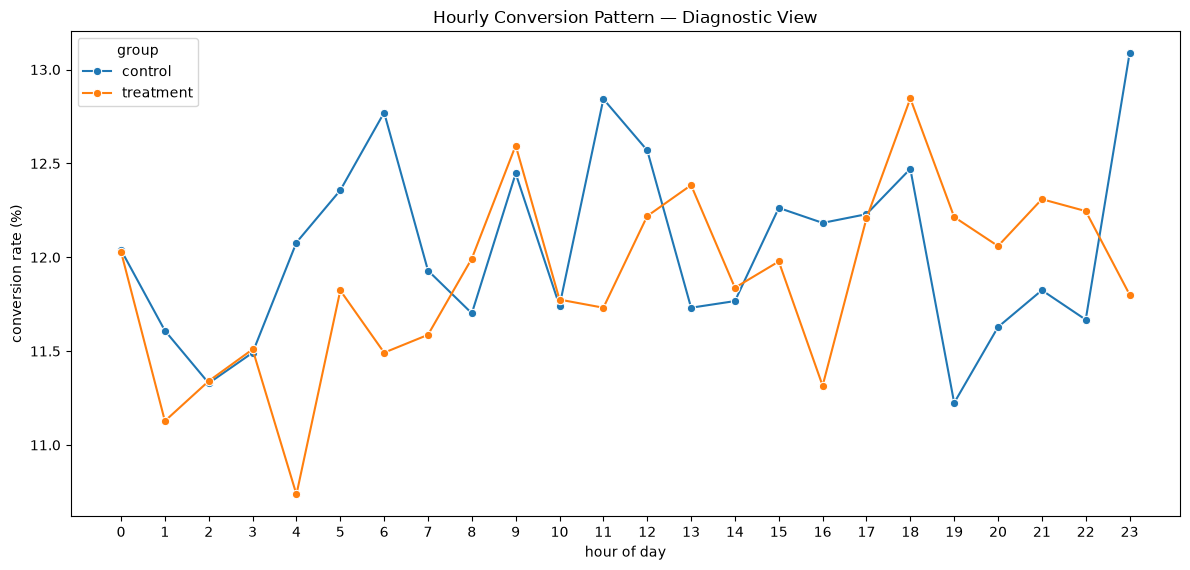

In [21]:
# a different time grain tests whether the overall gap is hiding reversals
plt.figure(figsize=(12, 5.8))
sns.lineplot(
    data=by_hour,
    x='hour',
    y='conversion_rate_pct',
    hue='group',
    marker='o'
)
plt.title('Hourly Conversion Pattern — Diagnostic View')
plt.xlabel('hour of day')
plt.ylabel('conversion rate (%)')
plt.xticks(range(24))
plt.legend(title='group')
plt.tight_layout()
plt.savefig(visual_dir / 'hourly conversion pattern.png', dpi=180, bbox_inches='tight')
plt.show()

In [22]:
# the interactive version keeps sample size available in the hover state
fig = px.line(
    by_hour,
    x='hour',
    y='conversion_rate_pct',
    color='group',
    markers=True,
    hover_data=['users', 'conversions'],
    title='Interactive Hourly Conversion Pattern'
)
fig.update_layout(
    xaxis_title='hour of day',
    yaxis_title='conversion rate (%)'
)
fig.write_html(
    visual_dir / 'interactive hourly conversion.html',
    include_plotlyjs='cdn'
)
fig.show()

In [23]:
# the sign of the hourly gap matters more than one isolated peak
hour_wide = by_hour.pivot(
    index='hour',
    columns='group',
    values='conversion_rate'
)
hour_wide['treatment_minus_control_pp'] = (
    hour_wide['treatment'] - hour_wide['control']
) * 100

print('hours treatment > control:', (hour_wide['treatment_minus_control_pp'] > 0).sum())
print('hours control > treatment:', (hour_wide['treatment_minus_control_pp'] < 0).sum())
display(hour_wide.sort_values('treatment_minus_control_pp').head(4))
display(hour_wide.sort_values('treatment_minus_control_pp', ascending=False).head(4))

hours treatment > control: 12
hours control > treatment: 12


group,control,treatment,treatment_minus_control_pp
hour,,,
4,0.120787,0.107365,-1.342198
23,0.130861,0.118014,-1.284686
6,0.127709,0.114918,-1.279117
11,0.128431,0.117312,-1.111914


group,control,treatment,treatment_minus_control_pp
hour,,,
19,0.112243,0.122144,0.990057
13,0.117312,0.123843,0.653071
22,0.116675,0.122459,0.578441
21,0.118244,0.123095,0.485096


Treatment leads in **12 of 24 hours**, so the hourly view is mixed rather than uniformly negative. The strongest treatment edge appears around **19:00 (+0.99 pp)**, while the largest deficit appears around **04:00 (-1.34 pp)**. Because the advantage reverses across hours and the overall rate is still lower, the segmentation does not create a launch case.

## Addition — Scale the Decision

A small percentage-point gap can be hard to interpret. Scaling the observed rates to one million users converts the same difference into an operational quantity without changing the underlying evidence.

In [24]:
# scaling the observed gap makes the business cost easier to read
per_million = pd.DataFrame({
    'group': ['control benchmark', 'treatment observed'],
    'conversions_per_million': [
        control_rate * 1_000_000,
        treatment_rate * 1_000_000
    ]
})
per_million['conversions_per_million'] = per_million['conversions_per_million'].round(0)
per_million

,group,conversions_per_million
0,control benchmark,120386.0
1,treatment observed,118808.0


In [25]:
# the treatment impact is expressed relative to the current page
extra_conversions_per_million = (
    treatment_rate - control_rate
) * 1_000_000

print(f'treatment impact per 1M users: {extra_conversions_per_million:,.0f} conversions')

treatment impact per 1M users: -1,578 conversions


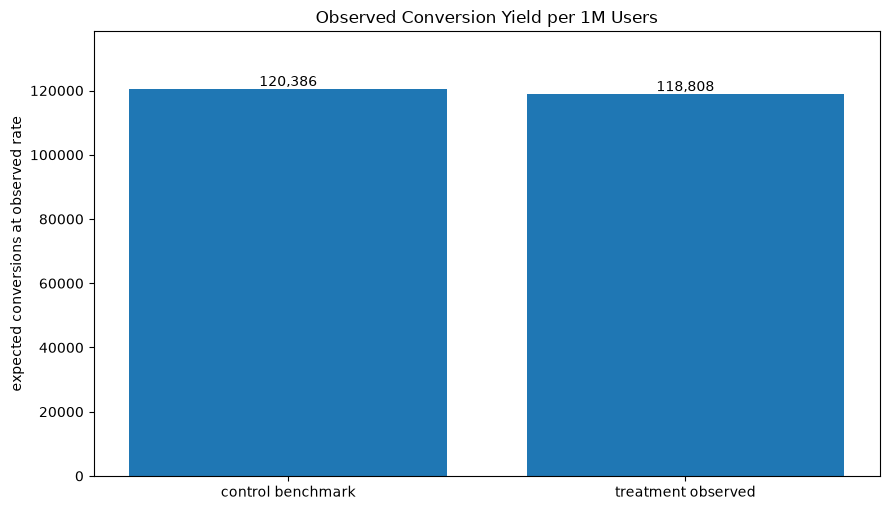

In [26]:
# same rates, translated into a business-scale comparison
plt.figure(figsize=(9, 5.2))
bars = plt.bar(
    per_million['group'],
    per_million['conversions_per_million']
)
plt.title('Observed Conversion Yield per 1M Users')
plt.ylabel('expected conversions at observed rate')
for bar, value in zip(bars, per_million['conversions_per_million']):
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value:,.0f}', ha='center', va='bottom')
plt.ylim(0, per_million['conversions_per_million'].max() * 1.15)
plt.tight_layout()
plt.savefig(visual_dir / 'conversion yield per million.png', dpi=180, bbox_inches='tight')
plt.show()

At the observed rates, one million control users correspond to roughly **120,386 conversions**, while the treatment rate corresponds to about **118,808**. That is an observed difference of approximately **-1,578 conversions per million users** in the treatment direction.

## Recommendation — Do Not Launch the New Page

The descriptive evidence does not support replacing the old page:

- control conversion rate: **12.04%**
- treatment conversion rate: **11.88%**
- treatment minus control: **-0.158 percentage points**
- relative treatment change: **-1.31%**
- scaled treatment impact: **-1,578 conversions per 1M users**
- control leads on **16 of 23** observed dates

**Decision:** keep the current page based on this descriptive read. The treatment does not show an observed conversion advantage, and the day-level check does not reveal a time window that overturns the overall direction.

This recommendation is intentionally limited to descriptive evidence. It does not claim statistical significance.

## Reproducibility Notes

- `converted` is treated as the binary business outcome.
- assignment mismatches are removed before calculating any KPI.
- repeated `user_id` values are reduced to the first valid timestamp.
- rates are calculated from user-level observations, not raw event rows.
- no inferential statistical test is used anywhere in the notebook.
- all exported visuals are written to the local `visuals/` folder.